In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_style("whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the CarDekho dataset

df = pd.read_csv("car data.csv")

print("Dataset loaded successfully!")

# Display first 5 rows
display(df.head())


Dataset loaded successfully!


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())


Dataset Shape: (301, 9)

Column Names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission    

In [4]:

# Generate statistical summary
display(df.describe(include='all'))


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,98,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.644115,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000


In [5]:

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Standardize categorical text values
df['Fuel_Type'] = df['Fuel_Type'].str.strip().str.title()
df['Seller_Type'] = df['Seller_Type'].str.strip().str.title()
df['Transmission'] = df['Transmission'].str.strip().str.title()

# Remove duplicate records
df = df.drop_duplicates().reset_index(drop=True)

print("Dataset cleaned successfully!")
print("Updated Dataset Shape:", df.shape)

# Check categorical values
print("\nFuel Types:")
print(df['Fuel_Type'].unique())

print("\nSeller Types:")
print(df['Seller_Type'].unique())

print("\nTransmission Types:")
print(df['Transmission'].unique())


Dataset cleaned successfully!
Updated Dataset Shape: (299, 9)

Fuel Types:
['Petrol' 'Diesel' 'Cng']

Seller Types:
['Dealer' 'Individual']

Transmission Types:
['Manual' 'Automatic']


In [6]:

print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nDuplicate Rows After Cleaning:", df.duplicated().sum())


Missing Values After Cleaning:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate Rows After Cleaning: 0


In [7]:

# Feature Engineering: Calculate Car Age

current_year = 2026

df['Car_Age'] = current_year - df['Year']

print("Car Age calculated successfully!")

display(df[['Car_Name', 'Year', 'Car_Age']].head())


Car Age calculated successfully!


,Car_Name,Year,Car_Age
0,ritz,2014,12
1,sx4,2013,13
2,ciaz,2017,9
3,wagon r,2011,15
4,swift,2014,12


In [8]:

# Extract brand from car name

df['Brand'] = df['Car_Name'].str.strip().str.split().str[0].str.title()

print("Car brands extracted successfully!")

display(df[['Car_Name', 'Brand', 'Car_Age']].head())

print("\nUnique Car Brands:")
print(df['Brand'].unique())


Car brands extracted successfully!


,Car_Name,Brand,Car_Age
0,ritz,Ritz,12
1,sx4,Sx4,13
2,ciaz,Ciaz,9
3,wagon r,Wagon,15
4,swift,Swift,12



Unique Car Brands:
['Ritz' 'Sx4' 'Ciaz' 'Wagon' 'Swift' 'Vitara' 'S' 'Alto' 'Ertiga' 'Dzire'
 'Ignis' '800' 'Baleno' 'Omni' 'Fortuner' 'Innova' 'Corolla' 'Etios'
 'Camry' 'Land' 'Royal' 'Um' 'Ktm' 'Bajaj' 'Hyosung' 'Mahindra' 'Honda'
 'Yamaha' 'Tvs' 'Hero' 'Activa' 'Suzuki' 'I20' 'Grand' 'I10' 'Eon' 'Xcent'
 'Elantra' 'Creta' 'Verna' 'City' 'Brio' 'Amaze' 'Jazz']


In [9]:

# Check updated dataset

print("Updated Dataset Shape:", df.shape)

display(df.head())


Updated Dataset Shape: (299, 11)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age,Brand
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0,12,Ritz
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0,13,Sx4
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0,9,Ciaz
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0,15,Wagon
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0,12,Swift


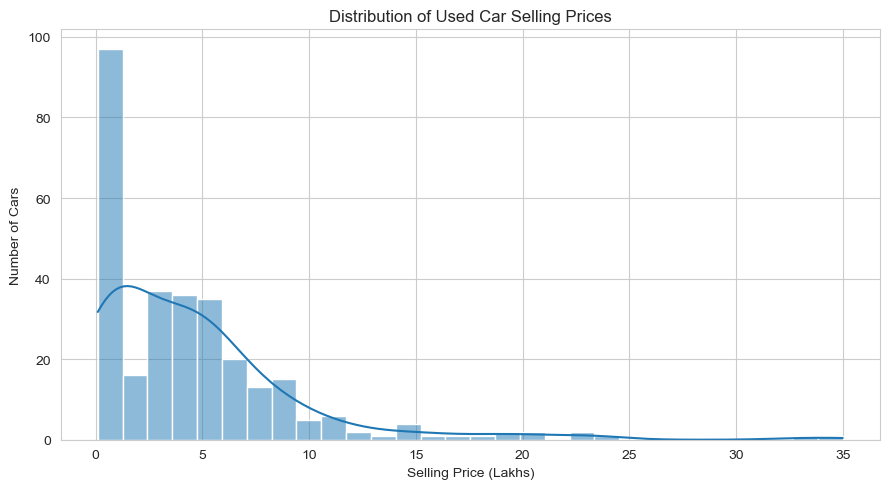

In [10]:

# Distribution of selling prices

plt.figure(figsize=(9, 5))

sns.histplot(df['Selling_Price'], bins=30, kde=True)

plt.title('Distribution of Used Car Selling Prices')
plt.xlabel('Selling Price (Lakhs)')
plt.ylabel('Number of Cars')

plt.tight_layout()
plt.show()


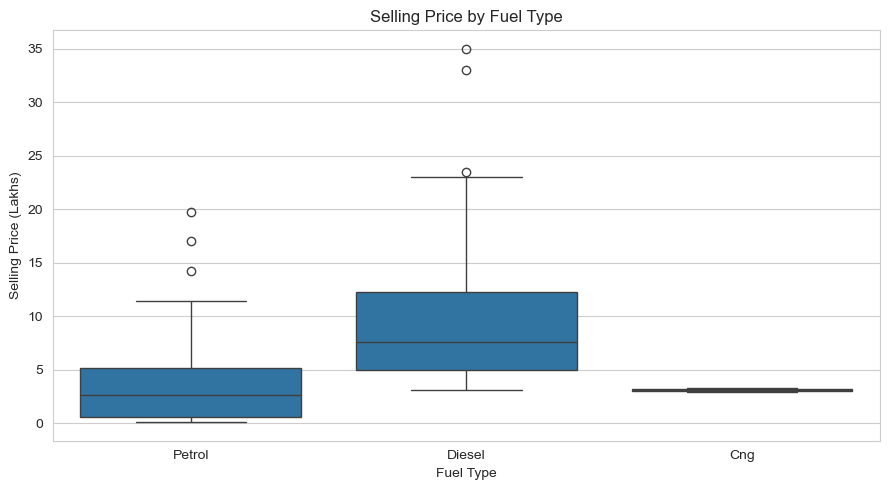

In [11]:

# Compare selling prices across fuel types

plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price')

plt.title('Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price (Lakhs)')

plt.tight_layout()
plt.show()


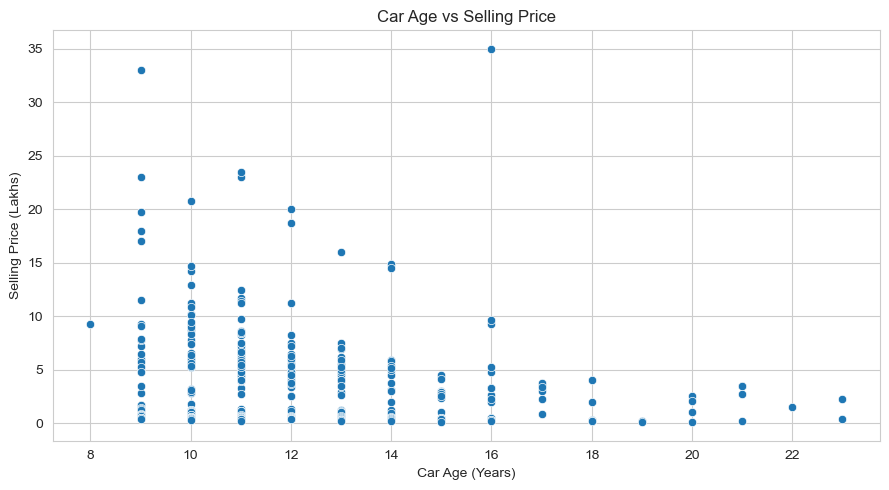

In [12]:

# Relationship between car age and selling price

plt.figure(figsize=(9, 5))

sns.scatterplot(data=df, x='Car_Age', y='Selling_Price')

plt.title('Car Age vs Selling Price')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price (Lakhs)')

plt.tight_layout()
plt.show()


In [13]:

# Select input features and target variable

X = df[['Present_Price', 'Kms_Driven', 'Fuel_Type',
        'Seller_Type', 'Transmission', 'Owner',
        'Car_Age', 'Brand']]

y = df['Selling_Price']

print("Input Features:")
display(X.head())

print("\nTarget Variable:")
display(y.head())


Input Features:


,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner,Car_Age,Brand
0,5.59,27000,Petrol,Dealer,Manual,0,12,Ritz
1,9.54,43000,Diesel,Dealer,Manual,0,13,Sx4
2,9.85,6900,Petrol,Dealer,Manual,0,9,Ciaz
3,4.15,5200,Petrol,Dealer,Manual,0,15,Wagon
4,6.87,42450,Diesel,Dealer,Manual,0,12,Swift



Target Variable:


0    3.35
1    4.75
2    7.25
3    2.85
4    4.60
Name: Selling_Price, dtype: float64

In [14]:

# Convert categorical variables into numerical values

X = pd.get_dummies(
    X,
    columns=['Fuel_Type', 'Seller_Type', 'Transmission', 'Brand'],
    drop_first=True,
    dtype=int
)

print("Categorical Encoding Completed!")
print("Updated Feature Shape:", X.shape)

display(X.head())


Categorical Encoding Completed!
Updated Feature Shape: (299, 51)


,Present_Price,Kms_Driven,Owner,Car_Age,Fuel_Type_Diesel,Fuel_Type_Petrol,Seller_Type_Individual,Transmission_Manual,Brand_Activa,Brand_Alto,...,Brand_Suzuki,Brand_Swift,Brand_Sx4,Brand_Tvs,Brand_Um,Brand_Verna,Brand_Vitara,Brand_Wagon,Brand_Xcent,Brand_Yamaha
0,5.59,27000,0,12,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9.54,43000,0,13,1,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,0
2,9.85,6900,0,9,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4.15,5200,0,15,0,1,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,6.87,42450,0,12,1,0,0,1,0,0,...,0,1,0,0,0,0,0,0,0,0


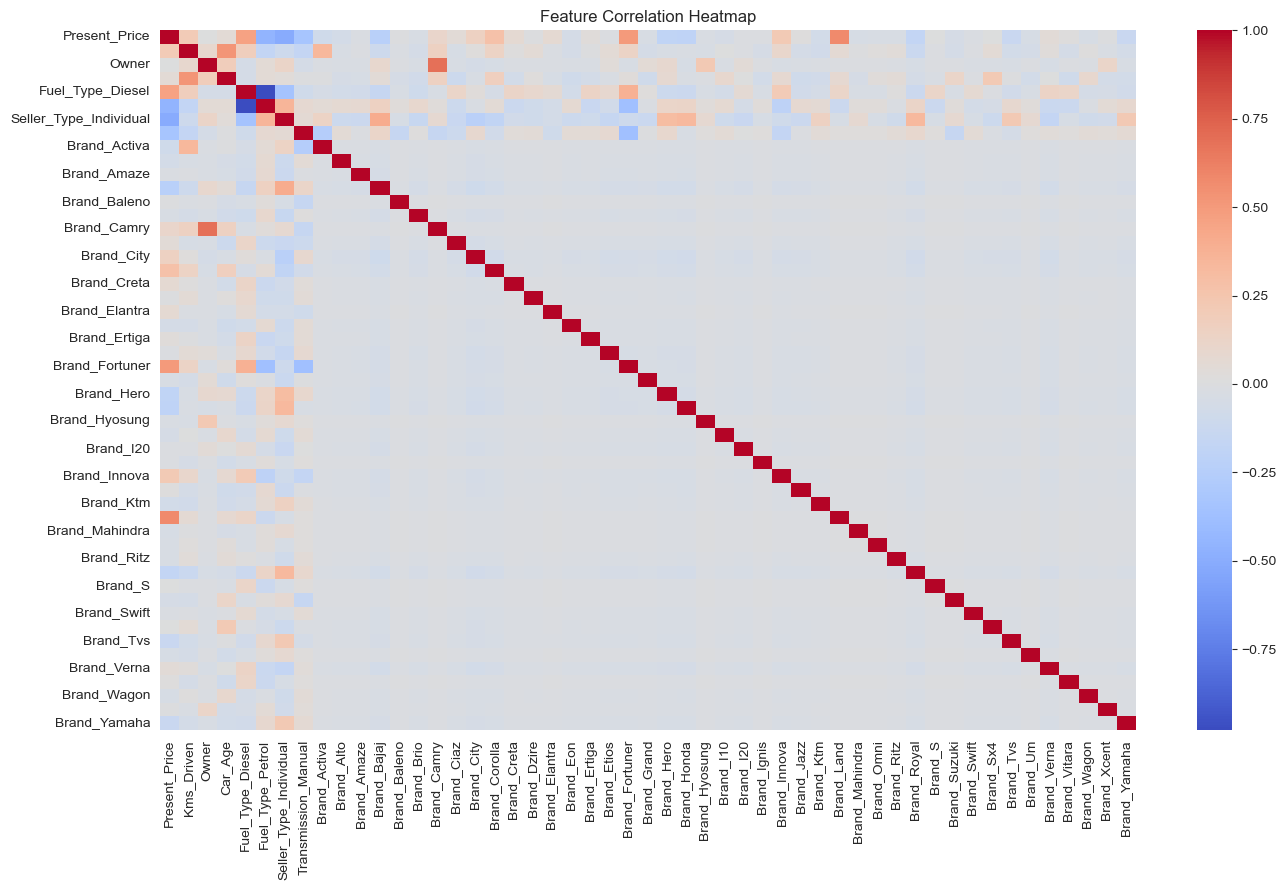

In [15]:

# Correlation between numerical features

plt.figure(figsize=(14, 9))

sns.heatmap(
    X.corr(),
    cmap='coolwarm',
    annot=False
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


In [16]:

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Data Splitting Completed!")

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Data Splitting Completed!
Training Features: (239, 51)
Testing Features: (60, 51)
Training Target: (239,)
Testing Target: (60,)


In [17]:

# Train Linear Regression model

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")


Linear Regression Model Trained Successfully!


In [18]:

# Train Random Forest Regression model

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [19]:

# Predict selling prices using both models

linear_predictions = linear_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 10 Actual Prices:")
print(y_test.head(10).values)

print("\nLinear Regression Predictions:")
print(linear_predictions[:10])

print("\nRandom Forest Predictions:")
print(rf_predictions[:10])


Predictions generated successfully!

First 10 Actual Prices:
[8.99 8.35 0.45 7.45 5.25 5.25 5.85 1.15 9.25 0.38]

Linear Regression Predictions:
[ 8.37270809  7.21310259  1.76151737  6.73624872 11.52964234  4.76396654
  8.69344442  1.82584385 13.33760568 -0.71633932]

Random Forest Predictions:
[ 9.5006   8.0286   0.43765  7.2075  16.19145  5.32325  6.6425   1.17725
  7.85625  0.3149 ]


In [20]:

# Function to evaluate regression models

def evaluate_model(actual, predicted, model_name):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print(f"\n{model_name}")
    print("---------------------------")
    print("MAE:", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2 Score:", round(r2, 3))

    return mae, rmse, r2


# Evaluate Linear Regression
linear_results = evaluate_model(
    y_test, linear_predictions, "Linear Regression"
)

# Evaluate Random Forest
rf_results = evaluate_model(
    y_test, rf_predictions, "Random Forest Regressor"
)



Linear Regression
---------------------------
MAE: 1.809
RMSE: 3.399
R2 Score: 0.552

Random Forest Regressor
---------------------------
MAE: 1.363
RMSE: 3.276
R2 Score: 0.583


In [21]:

# Create model comparison table

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [linear_results[0], rf_results[0]],
    'RMSE': [linear_results[1], rf_results[1]],
    'R2 Score': [linear_results[2], rf_results[2]]
})

display(comparison)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.808783,3.399321,0.551652
1,Random Forest,1.362621,3.276446,0.583479


In [22]:

# Select the best model based on R2 score

if rf_results[2] > linear_results[2]:
    best_model = rf_model
    best_model_name = "Random Forest Regressor"
else:
    best_model = linear_model
    best_model_name = "Linear Regression"

print("Best Performing Model:", best_model_name)


Best Performing Model: Random Forest Regressor


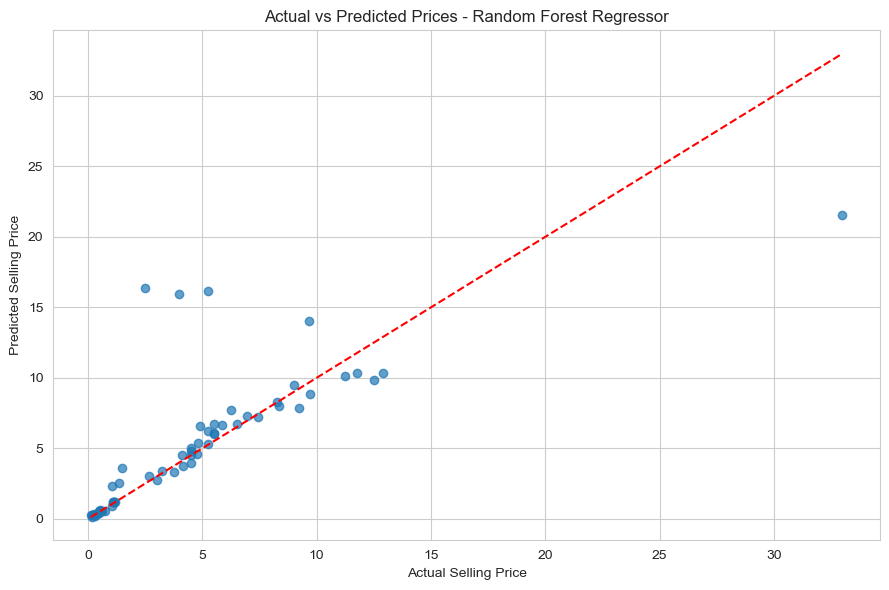

In [23]:

# Compare actual and predicted selling prices

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(9, 6))

plt.scatter(y_test, best_predictions, alpha=0.7)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title(f"Actual vs Predicted Prices - {best_model_name}")

# Reference line
minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], 'r--')

plt.tight_layout()
plt.show()


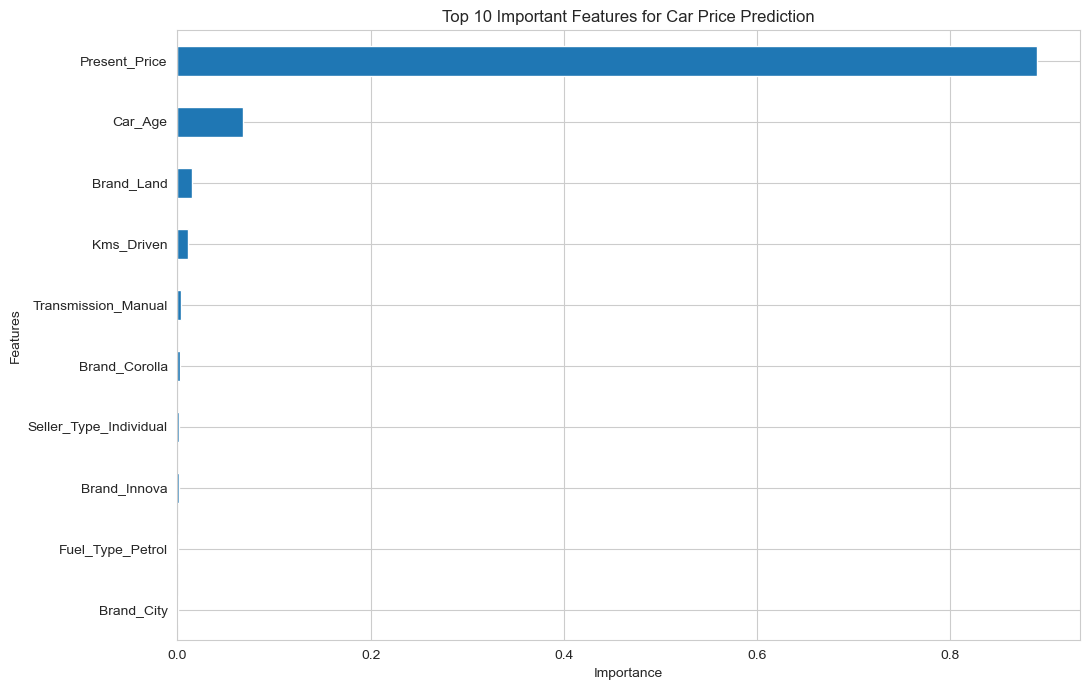

Present_Price             0.889730
Car_Age                   0.067575
Brand_Land                0.015326
Kms_Driven                0.011107
Transmission_Manual       0.004118
Brand_Corolla             0.002989
Seller_Type_Individual    0.002072
Brand_Innova              0.001785
Fuel_Type_Petrol          0.001055
Brand_City                0.000988
dtype: float64

In [24]:



# Feature importance using Random Forest

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(11, 7))

feature_importance.head(10).sort_values().plot(kind='barh')

plt.title("Top 10 Important Features for Car Price Prediction")
plt.xlabel("Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

display(feature_importance.head(10))


In [25]:

# Final Project Summary

print("========== CAR PRICE PREDICTION PROJECT ==========")

print("Total Records:", len(df))
print("Number of Car Brands:", df['Brand'].nunique())

print("\nBest Performing Model:", best_model_name)

print("\nModel Performance:")
display(comparison)

print("\nTop 5 Important Features:")
display(feature_importance.head(5))

print("\n========== PROJECT COMPLETED ==========")


========== CAR PRICE PREDICTION PROJECT ==========
Total Records: 299
Number of Car Brands: 44

Best Performing Model: Random Forest Regressor

Model Performance:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.808783,3.399321,0.551652
1,Random Forest,1.362621,3.276446,0.583479



Top 5 Important Features:


Present_Price          0.889730
Car_Age                0.067575
Brand_Land             0.015326
Kms_Driven             0.011107
Transmission_Manual    0.004118
dtype: float64


========== PROJECT COMPLETED ==========



## Key Observations

1. The dataset contains information about used cars and their selling prices.
2. Selling prices vary depending on factors such as present price, car age, fuel type, and mileage.
3. The fuel type box plot helps compare the price distribution of different fuel categories.
4. Car age and selling price show a relationship that helps understand vehicle depreciation.
5. Two regression models, Linear Regression and Random Forest, were trained and evaluated.
6. Model performance was compared using MAE, RMSE, and R² score.
7. Feature importance analysis identifies the features that contribute most to price predictions.



## Conclusion

This project developed a machine learning model to predict used car selling prices using Python. The dataset was cleaned, explored, and transformed using feature engineering and one-hot encoding. Linear Regression and Random Forest Regression were trained and evaluated using MAE, RMSE, and R² score. The best-performing model was selected based on its R² score. Feature importance analysis helped identify the major factors influencing car prices.
